# Assignment 2 Distribution Grid Simulation

## Notebook A

### Task 1

- Create with pandapower the distribution grid depicted below in figure 1
- Ressources:
    - online docs https://pandapower.readthedocs.io/en/latest/index.html

### Task 2

- Load the Dataset A for generation and load and perform a time series simulation.

- Ressources:
    - https://pandapower.readthedocs.io/en/latest/timeseries.html

### Task 3

- Explore how the allocation of the loads and generating elements influence the lines and external grid

![](fig_grid_A.png)
### Grid A

In [70]:
import pandapower as pp
import pandapower.plotting as plot
import pandas as pd
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

In [71]:
# create empty net
net = pp.create_empty_network()

# create buses
b1 = pp.create_bus(net, vn_kv=20.0, name="Bus 1")
b2 = pp.create_bus(net, vn_kv=0.4, name="Bus 2")
b3 = pp.create_bus(net, vn_kv=0.4, name="Bus 3")

# create bus elements
pp.create_ext_grid(net, bus=b1, vm_pu=1.02, name="Grid Connection")
pp.create_load(net, bus=b2, p_mw=0.1, q_mvar=0.005, name="Load")
pp.create_load(net, bus=b3, p_mw=0.1, q_mvar=0.005, name="Load")
pp.create_sgen(net, bus=b2, p_mw=0.1, q_mvar=0.005, name="Load")
pp.create_sgen(net, bus=b3, p_mw=0.1, q_mvar=0.005, name="Load")

# create branch elements
tid = pp.create_transformer(
    net, hv_bus=b1, lv_bus=b2, std_type="0.4 MVA 20/0.4 kV", name="Trafo"
)
pp.create_line(
    net, from_bus=b2, to_bus=b3, length_km=0.100, name="Line", std_type="NAYY 4x50 SE"
)

0

No or insufficient geodata available --> Creating artificial coordinates. This may take some time


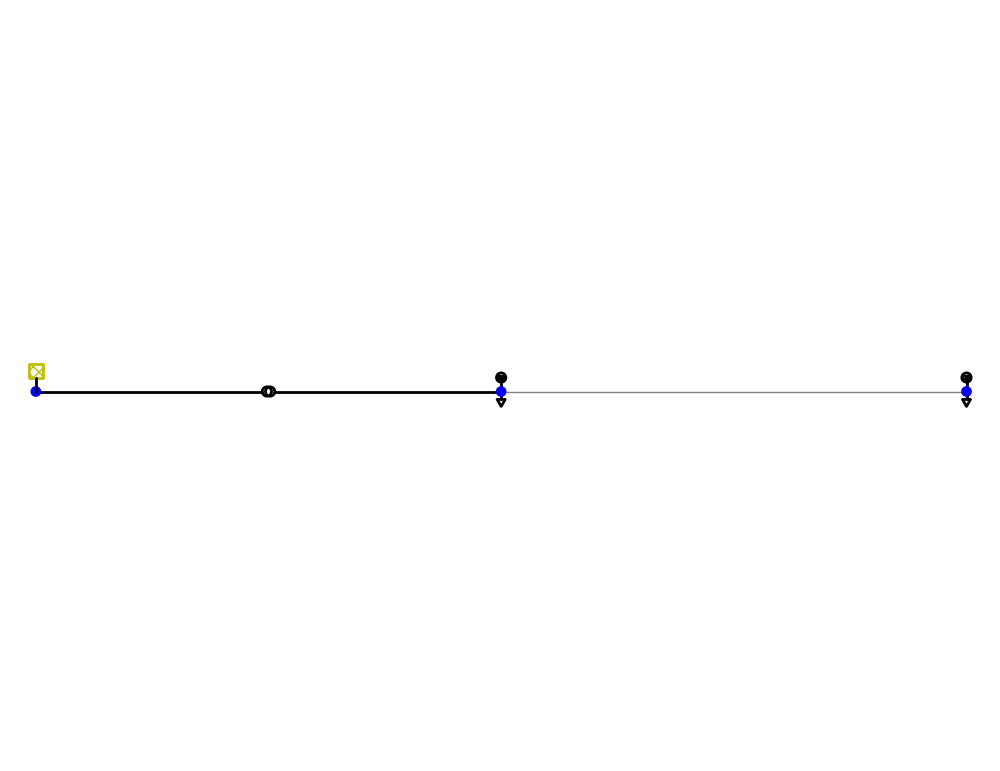

<Axes: >

In [72]:
plot.simple_plot(net, plot_loads=True, plot_sgens=True)

In [73]:
pp.runpp(net)
net.res_ext_grid

,p_mw,q_mvar
0,0.001405,-9.600074e-07


In [74]:
# load the dataframes from csv files
gen_data = pd.read_csv("../Data/GenerationData_A.csv", index_col=0)
gen_data.columns.name = "household"
load_data = pd.read_csv("../Data/LoadData_A.csv", index_col=0)
load_data.columns.name = "household"
load_data

household,0,1
0,0.000166,0.000163
1,0.000161,0.000170
2,0.000172,0.000161
3,0.000162,0.000181
4,0.000168,0.000173
5,0.000171,0.000323
6,0.000167,0.000180
7,0.000131,0.000143
8,0.000120,0.000192
9,0.000279,0.000225


<Axes: title={'center': 'Load and Generation Data Household 0'}, xlabel='Time of the Day [h]', ylabel='Generation [MW]'>

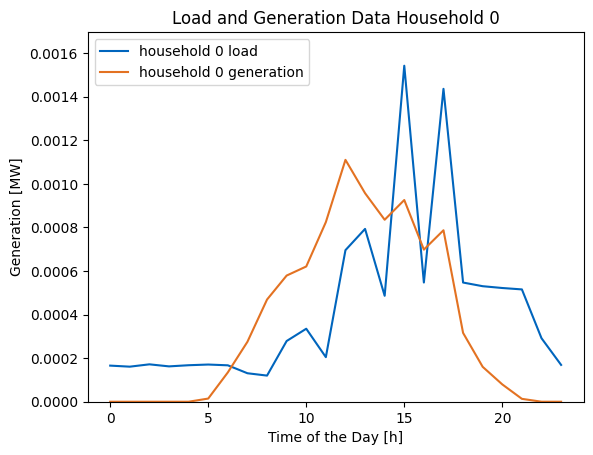

In [75]:
# plot household 0 load and generation data
load_data['0'].plot(legend=True, title="Load Data", xlabel="Time of the Day [h]", ylabel="Load [MW]", ylim=(0, 1.1 * load_data.max().max()), color=(0/255,101/255,189/255), label="household 0 load")
gen_data['0'].plot(legend=True, title="Load and Generation Data Household 0", xlabel="Time of the Day [h]", ylabel="Generation [MW]", ylim=(0, 1.1 * load_data.max().max()), color=(227/255,114/255,34/255), label="household 0 generation")

<Axes: title={'center': 'Load and Generation Data Household 1'}, xlabel='Time of the Day [h]', ylabel='Generation [MW]'>

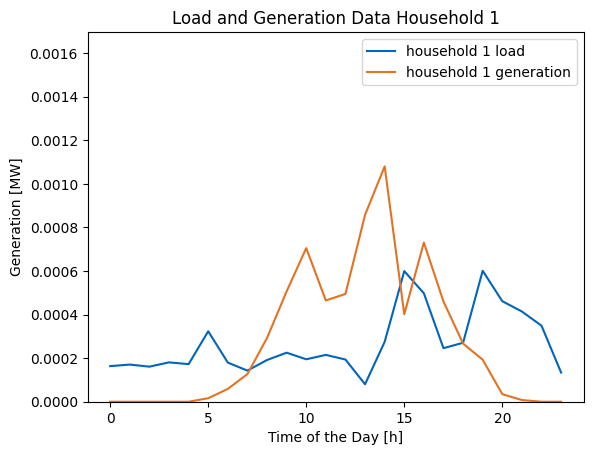

In [76]:
# plot generation data# plot household 1 load and generation data

load_data['1'].plot(legend=True, xlabel="Time of the Day [h]", ylabel="Load [MW]", ylim=(0, 1.1 * load_data.max().max()), color=(0/255,101/255,189/255), label="household 1 load")
gen_data['1'].plot(legend=True, title="Load and Generation Data Household 1", xlabel="Time of the Day [h]", ylabel="Generation [MW]", ylim=(0, 1.1 * load_data.max().max()), color=(227/255,114/255,34/255), label="household 1 generation")

In [77]:
# Subtract generation from load for each household and hour
net_load_df = load_data - gen_data

# Show result
net_load_df.head()

household,0,1
0,0.000166,0.000163
1,0.000161,0.000170
2,0.000172,0.000161
3,0.000162,0.000181
4,0.000168,0.000173


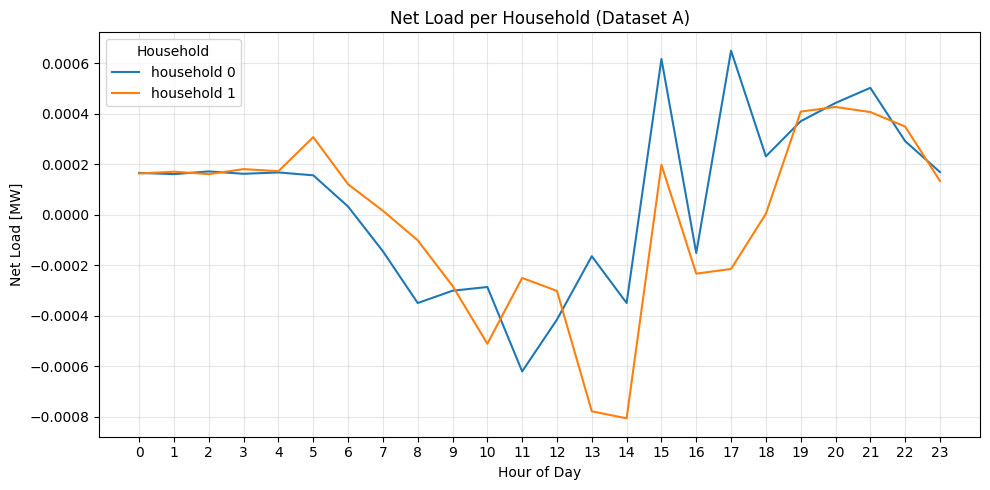

In [78]:
# Plot net load per household (A)
import matplotlib.pyplot as plt

net_load = net_load_df.copy()

# Plot
plt.figure(figsize=(10, 5))
for col in net_load.columns:
    plt.plot(net_load.index, net_load[col], marker=None, label=f"household {col}")

plt.title("Net Load per Household (Dataset A)")
plt.xlabel("Hour of Day")
plt.ylabel("Net Load [MW]")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.legend(title="Household")
plt.tight_layout()
plt.show()


In [79]:
# Calculate percentage of load covered by generation per hour per household (A)
import pandas as pd
import numpy as np
from pathlib import Path

gen = gen_data.copy()
load = load_data.copy()

# Treat very small values (order e-04) as zero to avoid huge ratios from tiny denominators
threshold = 1e-4
gen = gen.where(gen.abs() >= threshold, 0.0)
load = load.where(load.abs() >= threshold, 0.0)

# Compute percentage: (generation / load) * 100
# Use safe division: where load == 0, result will be NaN unless both are zero.
pct = gen.divide(load).replace([np.inf, -np.inf], np.nan) * 100

# Define convention for zero-load hours:
# - If both generation and load are zero -> coverage = 0%
# - If load == 0 and generation > 0 -> coverage = 100% (generation fully exceeds zero load)
both_zero = (gen == 0) & (load == 0)
load_zero_gen_pos = (load == 0) & (gen > 0)

pct = pct.where(~both_zero, 0.0)
pct = pct.where(~load_zero_gen_pos, 100.0)

print(f"Saved generation coverage (%) to: {pct}")


# Also print mean coverage per household across hours
mean_cov = pct.mean()
print("\nAverage coverage per household (%):")
print(mean_cov)


Saved generation coverage (%) to: household           0           1
0            0.000000    0.000000
1            0.000000    0.000000
2            0.000000    0.000000
3            0.000000    0.000000
4            0.000000    0.000000
5            0.000000    0.000000
6           80.501925    0.000000
7          210.483563   88.860475
8          391.101702  152.740612
9          207.839171  225.000020
10         185.284556  361.950462
11         402.968565  216.188944
12         159.577589  255.601858
13         120.671500  100.000000
14         171.799324  393.065419
15          60.027952   67.006434
16         127.592499  146.773687
17          54.797649  187.213722
18          57.737229   98.589535
19          30.194296   32.098184
20           0.000000    0.000000
21           0.000000    0.000000
22           0.000000    0.000000
23           0.000000    0.000000

Average coverage per household (%):
household
0    94.190730
1    96.878723
dtype: float64


In [80]:
# Summarize net load: total positive and total negative per household

# Sum positive values (net import to household) and negative values (net export from household)
positive_sum = net_load.clip(lower=0).sum()
negative_sum = net_load.clip(upper=0).sum()  # negative numbers (MWh if hourly sums)
negative_sum_abs = -negative_sum  # absolute exported energy

summary_df = pd.DataFrame({
    "positive_sum_MW_h": positive_sum,
    "negative_sum_MW_h": negative_sum,
    "negative_sum_abs_MW_h": negative_sum_abs
})

# Print nicely
print("Per-household Net Load Summary (sums over all hours):")
print(summary_df)

# Provide a short human-friendly summary
for house in summary_df.index:
    pos = summary_df.loc[house, "positive_sum_MW_h"]
    neg = summary_df.loc[house, "negative_sum_abs_MW_h"]
    print(f"Household {house}: Power_from_grid={pos:.6f}, Power_to_grid={neg:.6f}")


Per-household Net Load Summary (sums over all hours):
           positive_sum_MW_h  negative_sum_MW_h  negative_sum_abs_MW_h
household                                                             
0                   0.004289          -0.002778               0.002778
1                   0.003218          -0.003474               0.003474
Household 0: Power_from_grid=0.004289, Power_to_grid=0.002778
Household 1: Power_from_grid=0.003218, Power_to_grid=0.003474


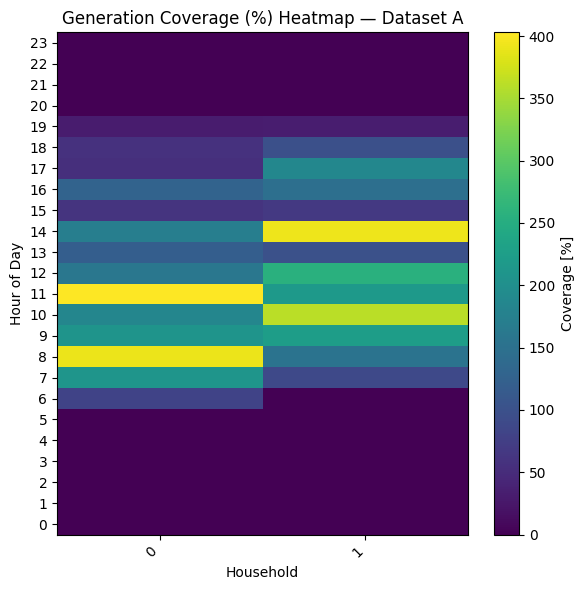

In [81]:
# Heatmap of generation coverage (%) per hour and household (A)

# Load coverage if saved, otherwise try to use in-notebook variables or compute from gen/load
cov = pct.copy()

# Prepare data for heatmap
data = cov.values
n_hours, n_houses = data.shape

# determine hour labels

hours = cov.index.astype(int).tolist()
houses = [str(c) for c in cov.columns]

# Plot heatmap
plt.figure(figsize=(max(6, n_houses * 1.2), 6))
im = plt.imshow(data, aspect='auto', cmap='viridis', origin='lower', vmin=0, vmax=cov.max().max())
cb = plt.colorbar(im, label='Coverage [%]')
plt.yticks(ticks=range(n_hours), labels=hours)
plt.xticks(ticks=range(n_houses), labels=houses, rotation=45, ha='right')
plt.xlabel('Household')
plt.ylabel('Hour of Day')
plt.title('Generation Coverage (%) Heatmap — Dataset A')
plt.tight_layout()
plt.show()



In [82]:
from utils import run_time_series

In [83]:
res_ext_1, res_lines_1 = run_time_series(
    gen_data,
    load_data,
    net,
    index_order_load=[0, 1],
    index_order_gen=[0, 1],
)
res_ext_2, res_lines_2 = run_time_series(
    gen_data,
    load_data,
    net,
    index_order_load=[1, 0],
    index_order_gen=[1, 0],
)

No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
100%|██████████| 24/24 [00:00<00:00, 50.64it/s]
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
100%|██████████| 24/24 [00:00<00:00, 44.88it/s]


In [84]:
res_lines_1.max(axis=1).sum()

6.668227537707473

In [85]:
res_lines_2.max(axis=1).sum()

7.043080869871139

In [86]:
all(res_lines_1.max(axis=1) <= 100)

True

<Axes: title={'center': 'Line Loading'}, xlabel='Time of the Day [h]', ylabel='Line Loading [%]'>

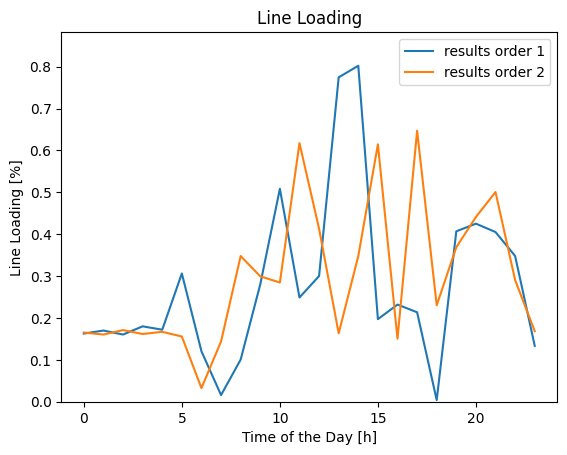

In [87]:
# plot res lines in one plot with legend
ax=res_lines_1['0'].plot(label="results order 1",legend=True, title="Line Loading", xlabel="Time of the Day [h]", ylabel="Line Loading [%]", ylim=(0, 1.1 * res_lines_1.max().max()))
res_lines_2['0'].plot(ax=ax, legend=True, title="Line Loading", xlabel="Time of the Day [h]", ylabel="Line Loading [%]", ylim=(0, 1.1 * res_lines_1.max().max()),label="results order 2")